In [1]:
import json
import sys
import time
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pyarrow.parquet as pq
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier

sys.path.append(str(Path("..").resolve()))
from src.preprocessing.sampling import stratified_sample_parquet
from src.preprocessing.features import select_features, signed_log1p, MaxImputer
from src.training.splits import behavior_keys, random_split, group_split, twin_rate
from src.evaluation.metrics import evaluate, plot_confusion

sns.set_theme(style="whitegrid")

In [2]:
PROCESSED_PATH = Path("../data/processed")
MERGED_FILE = PROCESSED_PATH / "merged" / "ddos_merged.parquet"
TRAINING_SAMPLE_FILE = PROCESSED_PATH / "training_sample.parquet"
FIGURES_PATH = Path("../reports/figures")
MODELS_PATH = Path("../saved_models")
MODELS_PATH.mkdir(parents=True, exist_ok=True)

SAMPLE_CAP_PER_CLASS = 300_000
TEST_SIZE = 0.2
SEED = 2026  # deliberately different from the EDA sample's seed (42)
LR_ROWS_PER_CLASS = 30_000  # see the experiments cell

class_dist = pd.read_csv("../reports/class_distribution.csv")
label_encoding = json.load(open("../reports/label_encoding.json"))
class_names = sorted(label_encoding, key=label_encoding.get)
candidate_features = json.load(open("../reports/feature_config.json"))["numeric_feature_columns"]

print("classes:", class_names)
print("candidate features:", len(candidate_features))

classes: ['BENIGN', 'DNS', 'LDAP', 'MSSQL', 'NTP', 'NetBIOS', 'Portmap', 'SNMP', 'SSDP', 'Syn', 'TFTP', 'UDP', 'UDPLag']
candidate features: 81


In [3]:
# Stream the 69.9M-row merged file once, keeping up to SAMPLE_CAP_PER_CLASS rows per
# class (smaller classes are kept whole). Flow ID is skipped: unique per flow, large,
# and never a feature.
class_counts = dict(zip(class_dist["Class"], class_dist["Rows"]))
sample_columns = [c for c in pq.ParquetFile(MERGED_FILE).schema_arrow.names if c != "Flow ID"]

data = stratified_sample_parquet(
    MERGED_FILE,
    class_counts=class_counts,
    cap_per_class=SAMPLE_CAP_PER_CLASS,
    seed=SEED,
    columns=sample_columns,
)
print(f"training sample: {len(data):,} rows")
data["Label"].value_counts()

training sample: 3,598,302 rows


Label
MSSQL      301579
SNMP       300812
DNS        300533
UDP        300530
NTP        300300
Syn        300155
TFTP       300013
LDAP       299631
SSDP       299625
UDPLag     299446
NetBIOS    299294
Portmap    186960
BENIGN     109424
Name: count, dtype: int64[pyarrow]

In [4]:
# A flow's "behavior" = every numeric feature except the two ports. Ephemeral ports
# differ on nearly every flow, so including them would hide the ~69% behavioral
# duplication measured during EDA.
PORT_COLUMNS = ["Source Port", "Destination Port"]
behavior_columns = [c for c in candidate_features if c not in PORT_COLUMNS]

data["behavior_key"] = behavior_keys(data, behavior_columns)
y = data["Label_Encoded"].to_numpy()
print(f"distinct behaviors: {data['behavior_key'].nunique():,} of {len(data):,} rows")

distinct behaviors: 944,986 of 3,598,302 rows


In [5]:
# Many flows are behaviorally IDENTICAL across attack labels -- e.g. two 1472-byte
# packets 1us apart (IP fragments of an amplified UDP response) appear under LDAP, DNS,
# SNMP and MSSQL alike. Identical inputs must get identical predictions, so without
# ports the best any model can do is predict each behavior's most common label.
# That gives a hard ceiling on what flow behavior alone can achieve.
per_behavior = data.groupby(["behavior_key", "Label"], observed=True).size().unstack(fill_value=0)
shared = per_behavior.index[(per_behavior > 0).sum(axis=1) > 1]
best_guess = data["behavior_key"].map(per_behavior.idxmax(axis=1))

ceiling = pd.Series(
    f1_score(data["Label"].astype(str), best_guess.astype(str), average=None, labels=class_names),
    index=class_names, name="behavior-only F1 ceiling",
)
ceiling.to_csv("../reports/behavior_ceiling.csv")

print(f"flows whose exact behavior also occurs under another label: {100 * data['behavior_key'].isin(shared).mean():.1f}%")
print(f"behavior-only ceiling -- macro-F1: {ceiling.mean():.4f}")
ceiling.round(3).sort_values().to_frame()

flows whose exact behavior also occurs under another label: 63.3%
behavior-only ceiling -- macro-F1: 0.8080


,behavior-only F1 ceiling
Portmap,0.526
DNS,0.648
LDAP,0.657
UDP,0.723
NetBIOS,0.732
SSDP,0.771
SNMP,0.783
UDPLag,0.851
Syn,0.865
MSSQL,0.955


In [6]:
data["split_random"] = np.where(random_split(y, TEST_SIZE, SEED), "test", "train")
data["split_group"] = np.where(group_split(y, data["behavior_key"], TEST_SIZE, SEED), "test", "train")

test_fraction = pd.DataFrame({
    protocol: data.loc[data[col] == "test", "Label"].value_counts() / data["Label"].value_counts()
    for protocol, col in [("random", "split_random"), ("group", "split_group")]
}).round(3)
test_fraction

,random,group
Label,,
BENIGN,0.2,0.2
DNS,0.2,0.2
LDAP,0.2,0.149
MSSQL,0.2,0.2
NTP,0.2,0.2
NetBIOS,0.2,0.128
Portmap,0.2,0.091
SNMP,0.2,0.2
SSDP,0.2,0.2


In [7]:
# How many test flows have an identical-behavior twin in training? High for the random
# split; 0% for the group split by construction.
keys = data["behavior_key"].to_numpy()
for protocol, col in [("random", "split_random"), ("group", "split_group")]:
    rate = twin_rate(keys, data[col].eq("test").to_numpy())
    print(f"{protocol:>6} split: {100 * rate:5.1f}% of test flows have a behavioral twin in training")

random split:  75.7% of test flows have a behavioral twin in training
 group split:   0.0% of test flows have a behavioral twin in training


In [8]:
data.to_parquet(TRAINING_SAMPLE_FILE, index=False, compression="snappy")
print(f"saved {TRAINING_SAMPLE_FILE} ({TRAINING_SAMPLE_FILE.stat().st_size / 1024**2:.1f} MB)")

saved ..\data\processed\training_sample.parquet (178.8 MB)


In [9]:
# Feature selection uses only rows that are training rows under BOTH protocols, so no
# test row from either protocol influences which features the models see.
# A feature is dropped only if redundant pooled AND within every class (|r| >= 0.99):
# pooled correlation alone would discard BENIGN-specific signal (see features.py).
fs_rows = data["split_random"].eq("train") & data["split_group"].eq("train")
features, constant, dropped = select_features(data.loc[fs_rows], candidate_features, "Label", threshold=0.99)
features_no_ports = [f for f in features if f not in PORT_COLUMNS]

print(f"candidate features:                     {len(candidate_features)}")
print(f"constant (dropped):                     {len(constant)}")
print(f"redundant within every class (dropped): {len(dropped)}")
print(f"final features:                         {len(features)}  ({len(features_no_ports)} without ports)")

with open("../reports/final_features.json", "w") as f:
    json.dump({"features": features, "constant_dropped": constant, "redundant_dropped": dropped}, f, indent=2)

pd.Series(dropped, name="kept instead").rename_axis("dropped feature").to_frame()

candidate features:                     81
constant (dropped):                     12
redundant within every class (dropped): 9
final features:                         60  (58 without ports)


,kept instead
dropped feature,
Subflow Fwd Packets,Total Fwd Packets
Subflow Bwd Packets,Total Backward Packets
Subflow Fwd Bytes,Total Length of Fwd Packets
Subflow Bwd Bytes,Total Length of Bwd Packets
Avg Fwd Segment Size,Fwd Packet Length Mean
Avg Bwd Segment Size,Bwd Packet Length Mean
Fwd Packets/s,Flow Packets/s
RST Flag Count,Fwd PSH Flags
Fwd Header Length.1,Fwd Header Length


In [10]:
def make_experiments(seed):
    xgboost = lambda: XGBClassifier(
        n_estimators=300, max_depth=8, learning_rate=0.1, tree_method="hist", n_jobs=-1, random_state=seed,
    )
    return {
        # Linear reference point. Needs imputation + scaling (the tree models handle NaN
        # natively). Trained on LR_ROWS_PER_CLASS per class: lbfgs needs 15+ min per fit
        # on ~3M rows, and a linear model's accuracy saturates far below that size.
        "LogisticRegression": (make_pipeline(
            MaxImputer(),
            FunctionTransformer(signed_log1p),
            StandardScaler(),
            LogisticRegression(max_iter=1000, class_weight="balanced", random_state=seed),
        ), features),
        # max_samples bounds each tree to 30% of rows: keeps time and memory reasonable.
        "RandomForest": (RandomForestClassifier(
            n_estimators=100, max_samples=0.3, class_weight="balanced", n_jobs=-1, random_state=seed,
        ), features),
        "XGBoost": (xgboost(), features),
        # Ablation: ports are the only information beyond the behavior-only ceiling, and
        # they are partly garbage (non-first IP fragments have no UDP header).
        "XGBoost (no ports)": (xgboost(), features_no_ports),
    }


def per_class_subsample(y_train, n_per_class, seed):
    rng = np.random.default_rng(seed)
    picked = [
        rng.choice(np.flatnonzero(y_train == c), size=min(n_per_class, int((y_train == c).sum())), replace=False)
        for c in np.unique(y_train)
    ]
    return np.sort(np.concatenate(picked))

In [11]:
results, per_class_tables, predictions = [], {}, {}

for protocol, col in [("random", "split_random"), ("group", "split_group")]:
    train = data[col].eq("train").to_numpy()
    y_train, y_test = y[train], y[~train]

    for name, (model, cols) in make_experiments(SEED).items():
        rows = per_class_subsample(y_train, LR_ROWS_PER_CLASS, SEED) if name == "LogisticRegression" else slice(None)
        X_fit = data.loc[train, cols].iloc[rows]
        y_fit = y_train[rows]
        fit_kwargs = {"sample_weight": compute_sample_weight("balanced", y_fit)} if isinstance(model, XGBClassifier) else {}

        start = time.time()
        model.fit(X_fit, y_fit, **fit_kwargs)
        y_pred = model.predict(data.loc[~train, cols])
        elapsed = time.time() - start

        summary, per_class = evaluate(y_test, y_pred, class_names)
        results.append({"protocol": protocol, "model": name, **summary, "seconds": round(elapsed, 1)})
        per_class_tables[(protocol, name)] = per_class
        predictions[(protocol, name)] = (y_test, y_pred)
        print(f"[{protocol:>6}] {name:<20} macro-F1 = {summary['macro_f1']:.4f}   ({elapsed:.0f}s)")

        # Random Forest is skipped: its trees on ~3M rows can run to several GB on disk.
        if name != "RandomForest":
            slug = name.replace(" (no ports)", "_no_ports")
            joblib.dump(model, MODELS_PATH / f"{slug}_{protocol}.joblib")

[random] LogisticRegression   macro-F1 = 0.6757   (107s)
[random] RandomForest         macro-F1 = 0.7809   (76s)
[random] XGBoost              macro-F1 = 0.7907   (629s)
[random] XGBoost (no ports)   macro-F1 = 0.7648   (649s)
[ group] LogisticRegression   macro-F1 = 0.6860   (101s)
[ group] RandomForest         macro-F1 = 0.7577   (88s)
[ group] XGBoost              macro-F1 = 0.7828   (742s)
[ group] XGBoost (no ports)   macro-F1 = 0.7596   (733s)


In [12]:
results_df = pd.DataFrame(results)
results_df.to_csv("../reports/baseline_results.csv", index=False)

print(f"behavior-only macro-F1 ceiling (no ports): {ceiling.mean():.4f}")
(results_df.pivot(index="model", columns="protocol", values="macro_f1")[["random", "group"]]
    .assign(gap=lambda d: d["random"] - d["group"])
    .round(4))

behavior-only macro-F1 ceiling (no ports): 0.8080


protocol,random,group,gap
model,,,
LogisticRegression,0.6757,0.6860,-0.0103
RandomForest,0.7809,0.7577,0.0231
XGBoost,0.7907,0.7828,0.0079
XGBoost (no ports),0.7648,0.7596,0.0052


In [13]:
per_class_f1 = pd.DataFrame(
    {f"{model} ({protocol})": table["f1"] for (protocol, model), table in per_class_tables.items()}
)
per_class_f1.insert(0, "ceiling (no ports)", ceiling)
per_class_f1 = per_class_f1.round(3)
per_class_f1.to_csv("../reports/baseline_per_class_f1.csv")
per_class_f1

,ceiling (no ports),LogisticRegression (random),RandomForest (random),XGBoost (random),XGBoost (no ports) (random),LogisticRegression (group),RandomForest (group),XGBoost (group),XGBoost (no ports) (group)
BENIGN,1.000,0.988,0.999,1.000,0.999,0.970,0.996,1.000,0.997
DNS,0.648,0.508,0.686,0.687,0.608,0.446,0.655,0.687,0.602
LDAP,0.657,0.566,0.651,0.686,0.637,0.436,0.517,0.559,0.435
MSSQL,0.955,0.723,0.980,0.979,0.935,0.832,0.976,0.978,0.918
NTP,0.998,0.968,0.998,0.998,0.996,0.972,0.996,0.996,0.995
NetBIOS,0.732,0.473,0.671,0.690,0.556,0.611,0.748,0.775,0.726
Portmap,0.526,0.576,0.570,0.602,0.626,0.369,0.315,0.415,0.491
SNMP,0.783,0.677,0.795,0.800,0.763,0.653,0.713,0.756,0.713
SSDP,0.771,0.403,0.577,0.641,0.641,0.390,0.542,0.604,0.600
Syn,0.865,0.859,0.857,0.861,0.861,0.959,0.958,0.961,0.962


best baseline: XGBoost


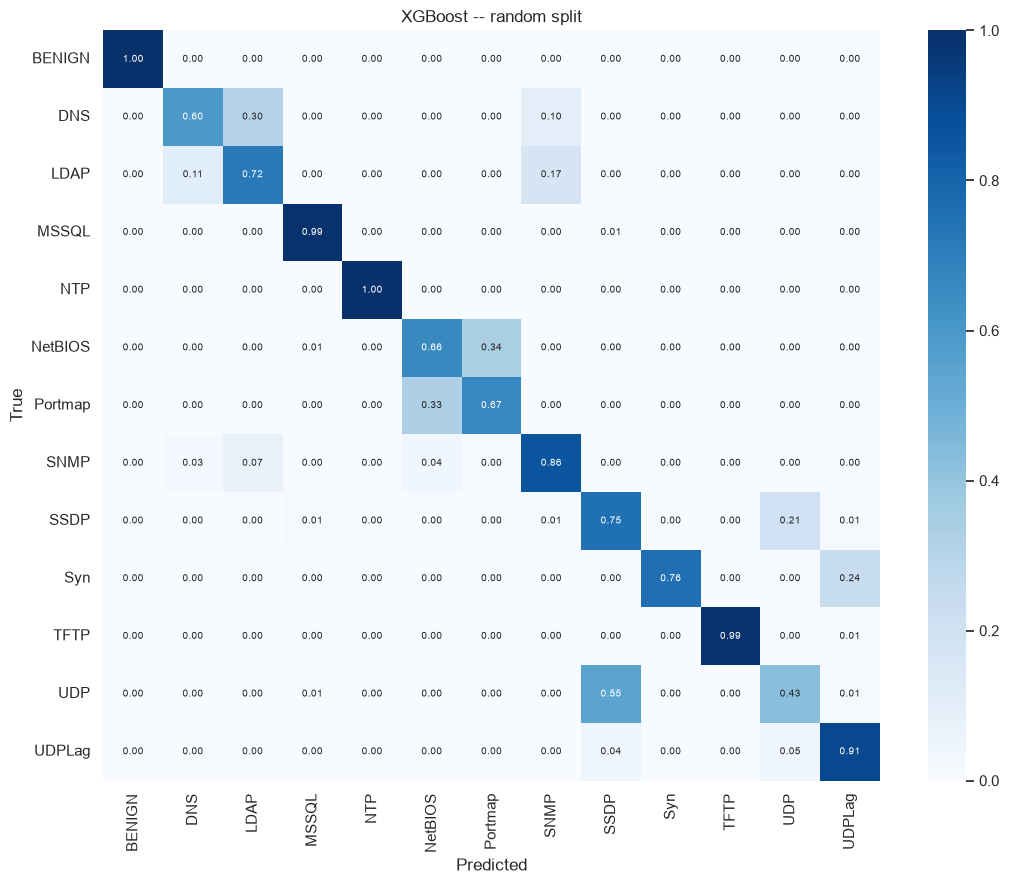

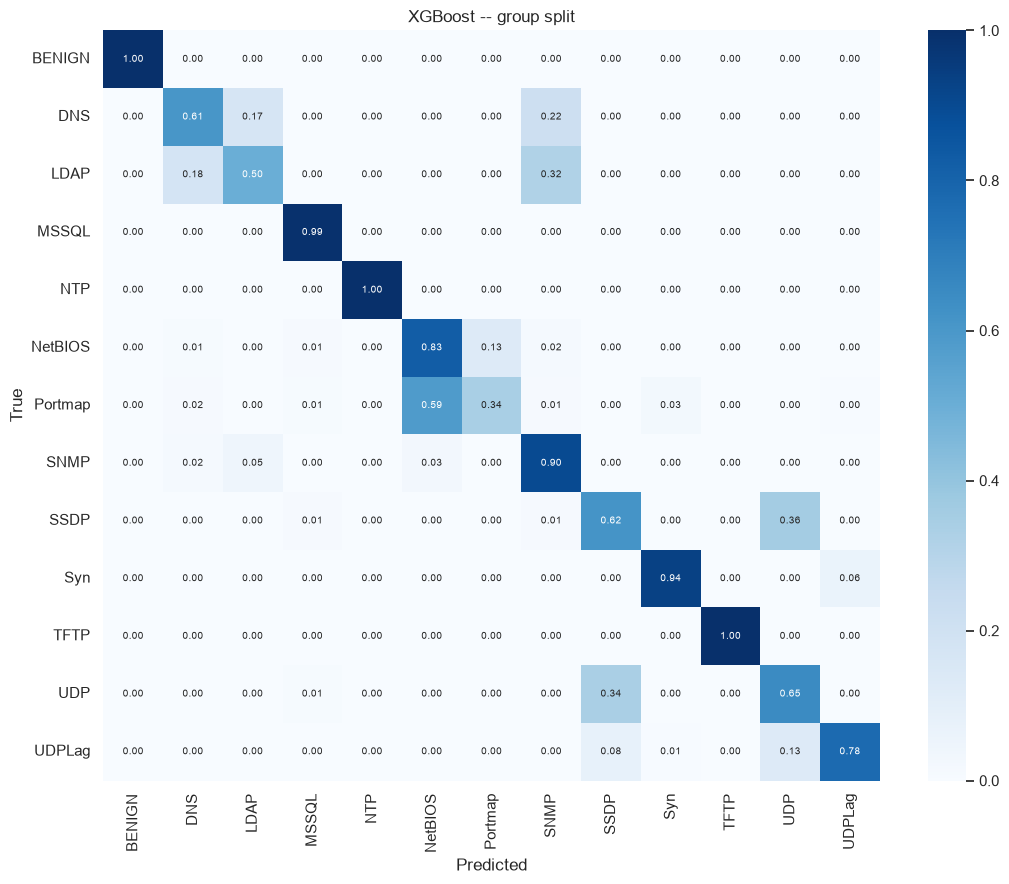

In [14]:
best_model = results_df.groupby("model")["macro_f1"].mean().idxmax()
print("best baseline:", best_model)

for protocol in ["random", "group"]:
    y_true, y_pred = predictions[(protocol, best_model)]
    plot_confusion(y_true, y_pred, class_names, f"{best_model} -- {protocol} split",
                   FIGURES_PATH / f"confusion_{best_model.replace(' ', '_')}_{protocol}.png")
    plt.show()